# Lab: Visualizing Text Data

Select **two distinct text datasets**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of figures for each question**, for a total of two research questions and four figures.

Each pair of figures should provide complementary evidence about the text. You may use Seaborn, Matplotlib, Plotly Express, or WordCloud. Choose datasets whose language is **work appropriate**.


## Learning goals

- Select and document usable text datasets.
- Ask focused questions about vocabulary, text length, or differences between groups.
- Prepare text reproducibly while preserving original wording for context checks.
- Choose and interpret two complementary figures per question.
- Distinguish word occurrences from the number or percentage of documents containing a word.
- Support conclusions with checked evidence and explain the limitations of the data and displays.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.


## Select your two datasets

Each dataset needs:

- A documented source and definitions for the features you use.
- Actual text, such as headlines, posts, descriptions, reviews, or passages—not only ratings or precomputed sentiment scores.
- Enough separate documents or passages to support your question. Define what one row represents.
- Relevant group labels if you plan to compare categories, authors, sources, or ratings. Document any groups you create.

Use two distinct datasets, not two filters of the same collection. A comparison of two categories from one collection counts as **one dataset and one investigation**. Choose your own questions rather than repeating the SMS lecture. Other documented sources are welcome.

Choose a manageable subset before analysis and document any sampling and its random seed. Save fixed copies in this notebook's `data` folder and use relative paths. Preserve the original text alongside prepared features. If you assemble passages from books, document their boundaries and retain book and author identifiers; passages from one book are not independent samples of all literature.

### Work-appropriate language

Be mindful that your datasets should be **work appropriate** for a classroom presentation. Read sample records and review the words, excerpts, and hover text that your figures will display. Public availability does not guarantee appropriate content. Choose another source or document any content-based exclusions when needed; explain how screening may affect your results. Review the final outputs before submitting. The suggestions below have not been screened for you.


### Candidate datasets

| Candidate and source | Useful text and grouping information | Possible question and figure pair |
| --- | --- | --- |
| [UCI News Aggregator](https://archive.ics.uci.edu/dataset/359/news+aggregator) | News titles, category, publisher, and story identifiers. Use `newsCorpora.csv` and its README; analyze titles rather than assuming the file contains full articles. Start with two categories and a manageable sample. | How does vocabulary differ between business and science/technology headlines? Use a word-frequency bar chart and a word-frequency scatter plot. Repeated coverage of the same story may affect counts. |
| [20 Newsgroups through scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html) | Posts and topic labels. Consider `rec.sport.baseball` and `sci.space`. The loader supports selecting categories and removing headers, footers, and quoted replies. Save the selected text and labels locally. | How do vocabulary and post length differ between baseball and space discussions? Use grouped word-frequency bars and a text-length box plot. Screen the posts; topic selection does not guarantee clean language. |
| [Project Gutenberg](https://www.gutenberg.org/) | Downloadable books with author and title information. Assemble a collection of clearly defined passages or chapters from selected books and preserve their source identifiers. Remove book headers and license boilerplate from the analysis copy. | Which words characterize selected adventure and nature-writing books? Use word clouds and a grouped word-frequency chart. Multiple books per group support a broader comparison than one book per group. |

Adapt the question to the available fields. A second pair of categories from the same collection does not satisfy the second-dataset requirement. The questions and chart pairs are starting points, not required choices.


## Choose two complementary figures per question

Choose **different chart types**, not two versions differing only in color, title, selected words, or counts versus percentages. You may reuse a chart type for the second dataset. A group of word clouds counts as one figure type; it cannot supply both figures by itself. At least one figure per question must support a numerical comparison, such as a bar chart, scatter plot, box plot, or heatmap.

| Figure | Tools | What it can help you see |
| --- | --- | --- |
| Word cloud | `WordCloud` and Matplotlib | An initial impression of prominent vocabulary. Each cloud scales its own words; font sizes are not precise comparisons across clouds. |
| Word-frequency bar chart | `sns.barplot()` or `px.bar()` | Exact occurrences or the percentage of documents containing selected words. State the denominator and use the same word selection across groups. |
| Word-frequency scatter plot | `px.scatter()` | Each point is a word, with its document percentage in group A on x and group B on y. Use equal scales and an equal-percentage reference line. |
| Text-length box plot or histogram | `sns.boxplot()`, `sns.histplot()`, `px.box()`, or `px.histogram()` | How document lengths vary within or across groups. Define length in words or characters. Length alone does not measure sentiment or quality. |
| Word-by-group heatmap—an additional option | `sns.heatmap()` or `px.imshow()` | How the percentage of documents containing a word varies across several groups. Use one common color scale and state its units. |

Keep different measures in separate figures. Explain how each figure helps answer the same research question. A plot of group sizes is useful context, but it cannot replace a required text-analysis figure unless it directly answers your question about the text.


### Preparation and interpretation guidance

- Preserve an original-text column and a document identifier. Decide how to handle blank text, duplicates, URLs, punctuation, case, and boilerplate.
- Start with scikit-learn's `ENGLISH_STOP_WORDS` for English text, then use an editable `additional_stopwords` list as in the lecture. Justify additions and apply the same choices to compared groups. Other languages need appropriate preparation.
- Report how many documents are in each group. Unequal numbers of documents and different document lengths affect raw word counts.
- **Word occurrences** count every repetition. **Percent of documents containing a word** counts each document once, divided by all documents in that group, including documents without the word. This is not the percentage of a word's matches that belong to a group.
- Define and document any display threshold or top-word selection. A word absent from the displayed chart is not necessarily absent from the data.
- Use descriptive titles, readable labels, common scales for common measures, and useful hover information where applicable. Keep counts and percentages on separate figures.
- Reuse or adapt the lecture's preparation and sample-message function, explaining your changes. No classifier, sentiment model, or train/test split is required.


### Starting pattern for an additional chart type

This is an **adaptation example**, not code to run unchanged. It assumes `tokens_df` has one row per retained word occurrence, with `document_id`, `group`, and `word`, and `documents_df` has one row per document. Replace these names with yours.

```python
# Count each document once per word, even if the word repeats.
word_counts = tokens_df.groupby(['group', 'word'])['document_id'].nunique().reset_index(name='documents_with_word')
group_sizes = documents_df.groupby('group')['document_id'].nunique()
word_counts['percent_documents'] = 100 * word_counts['documents_with_word'] / word_counts['group'].map(group_sizes)

# Show the ten words occurring in the most documents overall.
selected_words = tokens_df.groupby('word')['document_id'].nunique().nlargest(10).index
grid = word_counts.pivot(index='word', columns='group', values='percent_documents')
grid = grid.reindex(index=selected_words, columns=group_sizes.index).fillna(0)
sns.heatmap(grid, annot=True, fmt='.1f', cmap='Blues',
            cbar_kws={'label': 'Percent of documents in each group containing the word'})
plt.xlabel('Group')
plt.ylabel('Word')
plt.title('Selected vocabulary across groups')
plt.show()
```

Use unique document IDs across the collection. Here zero means no retained occurrence was observed in a group with documents; it does not replace missing source text. Choose a manageable number of words and groups so labels remain readable.


In [39]:
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

word_pattern = r"[A-Za-z]+(?:['’][A-Za-z]+)?"
screen_pattern = r"\b(?:fuck\w*|shit\w*|bitch\w*|cunt\w*|damn\w*|hell|nigger\w*)\b"


def prepare_documents(data, text_column):
    documents = data.copy()
    raw_text = documents[text_column]
    keep = raw_text.notna() & raw_text.str.strip().ne('')
    keep &= ~raw_text.str.contains(screen_pattern, case=False, na=False)
    documents = documents.loc[keep].copy()
    documents['words'] = documents[text_column].str.lower().str.findall(word_pattern)
    documents['word_count'] = documents['words'].str.len()
    return documents


def document_percentages(documents, group_column, words):
    summary = []
    for group, rows in documents.groupby(group_column):
        for word in words:
            count = rows['words'].map(lambda tokens: word in tokens).sum()
            summary.append({
                group_column: group,
                'word': word,
                'documents_with_word': count,
                'group_documents': len(rows),
                'percent': 100 * count / len(rows)
            })
    return pd.DataFrame(summary)

## Investigation 1: Your dataset and research question


### Step 1: Question

Ask one focused question about the text. Identify the documents, groups if relevant, and the vocabulary or text-derived feature you will examine. Record a prediction before producing figures.


**What is your research question, and what do you predict? Why is text analysis useful for answering it?**

Your answer: Do January 2025 federal rule and proposed-rule titles differ in length and word choice? I expect proposed titles to be longer and for rule titles to use words like regulations more often. Counting words gives me a way to check both ideas.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Identify blank text separately from missing values.


**Give the dataset title, publisher, direct source URL, feature-definition reference, and access date. Identify your saved files.**

Your answer: I saved the Federal Register titles from the Office of the Federal Register and Government Publishing Office as `data/federal_register_titles.csv` on November 15, 2026. I used the first 100 results from each document type, sorted oldest first within January 2025. See the [API field definitions](https://www.federalregister.gov/developers/documentation/api/v1) and the [Rule results](https://www.federalregister.gov/api/v1/documents.json?conditions%5Btype%5D%5B%5D=RULE&conditions%5Bpublication_date%5D%5Bgte%5D=01%2F01%2F2025&conditions%5Bpublication_date%5D%5Blte%5D=01%2F31%2F2025&per_page=100&order=oldest) and [Proposed Rule results](https://www.federalregister.gov/api/v1/documents.json?conditions%5Btype%5D%5B%5D=PRORULE&conditions%5Bpublication_date%5D%5Bgte%5D=01%2F01%2F2025&conditions%5Bpublication_date%5D%5Blte%5D=01%2F31%2F2025&per_page=100&order=oldest).

**What does one row represent? What texts and groups are covered, and how were they collected? How did you check that the language and displayed examples are work appropriate?**

Your answer: Each row is one official document title. The rules are from Jan. 2-14 and the proposed rules are from Jan. 2-17. I checked the titles for common swear words and read the examples shown below.

In [40]:
rules_df = pd.read_csv('data/federal_register_titles.csv', dtype=str)

In [41]:
rules_df.head()

,document_number,title,type,publication_date
0,2024-31017,Definition of Unreasonable Refusal To Deal or ...,Rule,2025-01-02
1,2024-31204,Civil Monetary Penalty Adjustments for Inflation,Rule,2025-01-02
2,2024-31220,"Presumptive Service Connection for Bladder, Ur...",Rule,2025-01-02
3,2024-31500,Airworthiness Directives; Airbus Helicopters D...,Rule,2025-01-02
4,2024-31510,Airworthiness Directives; Airbus Helicopters,Rule,2025-01-02


In [42]:
rules_df.tail()

,document_number,title,type,publication_date
195,2025-00955,"Major Food Allergen Labeling for Wines, Distil...",Proposed Rule,2025-01-17
196,2025-00957,Alcohol Facts Statements in the Labeling of Wi...,Proposed Rule,2025-01-17
197,2025-00964,Energy Conservation Program: Energy Conservati...,Proposed Rule,2025-01-17
198,2025-00965,Energy Conservation Program: Energy Conservati...,Proposed Rule,2025-01-17
199,2025-00966,Energy Conservation Program: Energy Conservati...,Proposed Rule,2025-01-17


In [43]:
rules_df.shape

(200, 4)

In [44]:
rules_df.info()
display(rules_df.isna().sum())
print('Blank titles:', rules_df['title'].str.strip().eq('').sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   document_number   200 non-null    str  
 1   title             200 non-null    str  
 2   type              200 non-null    str  
 3   publication_date  200 non-null    str  
dtypes: str(4)
memory usage: 29.4 KB


document_number     0
title               0
type                0
publication_date    0
dtype: int64

Blank titles: 0


**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| document_number | Federal Register document ID | Categorical | str | 0 |
| title | Original document title | Text | str | 0 |
| type | Rule or Proposed Rule | Categorical | str | 0 |
| publication_date | Date published in YYYY-MM-DD form | Temporal | str | 0 |

Use text, quantitative, categorical, or temporal for feature type.

Your answer: All four source fields were stored as strings and had 0 missing values.

**Which records and features will you use? Explain your groups, sampling, missing or blank text, duplicates, content screening, and text-preparation decisions, including stopwords.**

Your answer: I took the first 100 rules and 100 proposed rules in date order, so there was no random seed. No titles were missing, blank, or flagged. I kept six repeated titles because they had different IDs. I kept the original text and used a lowercase copy to count words made of letters, keeping apostrophes inside words. I counted every word for title length. The bar chart uses six words outside the standard stopword list. I added no extra stopwords.

In [45]:
rules = prepare_documents(rules_df, 'title')
print('Original:', len(rules_df), '| Retained:', len(rules))
print('Repeated titles:', rules_df['title'].duplicated().sum())
assert rules['document_number'].is_unique
rules.groupby('type')['word_count'].agg(['size', 'median', 'max'])

Original: 200 | Retained: 200
Repeated titles: 6


,size,median,max
type,,,
Proposed Rule,100,11.0,32
Rule,100,9.0,93


**How many records were removed from the dataset? Explain why, and state what one row represents in each analysis table.**

Your answer: I removed 0 of the 200 saved records. The analysis table still has one row per document. The word summary has one row per selected word and document type.

### Step 3: Evidence

Create two different figure types that answer this same question. At least one must support a numerical comparison. Use consistent preparation and explain any difference in the records or words displayed.


**Which two chart types will you use, and what should each make easier to answer? Specify what positions, colors, and sizes represent and define any percentage denominator.**

Your answer: The box plot shows how many words are in each type of title. The bar chart puts six words along the bottom and uses color for the title type. Bar height shows the percent of all 100 titles of that type that use the word at least once.

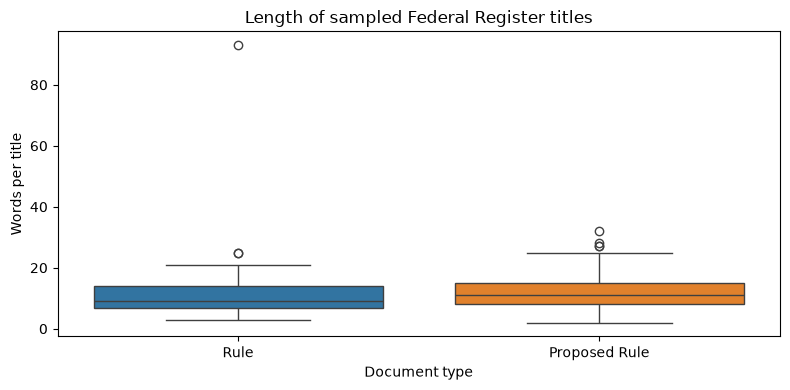

In [46]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=rules, x='type', y='word_count', hue='type', legend=False)
plt.title('Length of sampled Federal Register titles')
plt.xlabel('Document type')
plt.ylabel('Words per title')
plt.tight_layout()
plt.show()

**What does Figure 1 show? Describe a pattern and record at least one supporting value, identifying its word or text feature, group, and units.**

Your answer: The median proposed title had 11 words, compared with 9 for rules. Some rule titles were much longer. The longest had 93 words.

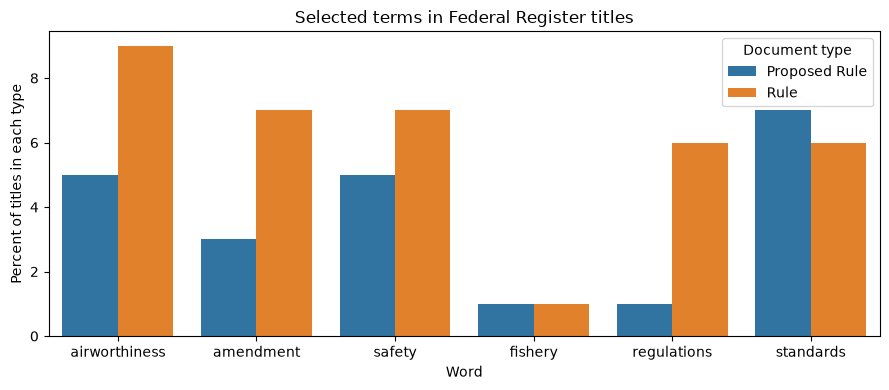

In [47]:
rule_words = ['airworthiness', 'amendment', 'safety', 'fishery', 'regulations', 'standards']
rule_terms = document_percentages(rules, 'type', rule_words)
plt.figure(figsize=(9, 4))
sns.barplot(data=rule_terms, x='word', y='percent', hue='type', order=rule_words)
plt.title('Selected terms in Federal Register titles')
plt.xlabel('Word')
plt.ylabel('Percent of titles in each type')
plt.legend(title='Document type')
plt.tight_layout()
plt.show()

**What does Figure 2 add? Record at least one supporting value and compare its message with Figure 1.**

Your answer: The word chart shows what the titles talk about. Airworthiness appeared in 9 of 100 rule titles and 5 of 100 proposed-rule titles. The box plot only shows how long the titles are.

### Step 4: Check

Verify at least two plotted values against records or calculated summaries. Read a few original texts containing a selected word or illustrating a pattern, using the lecture's sample function or your own code. For grouped comparisons, check examples from each relevant group when matches exist. Explain whether context supports your interpretation. Do not repeat the initial missing-value count.


In [48]:
rule_titles = rules_df.loc[rules_df['type'] == 'Rule', 'title']
rule_median = rule_titles.map(lambda title: len(re.findall(word_pattern, title))).median()
rule_matches = rule_titles.str.contains(r'\bairworthiness\b', case=False)
plotted_rule = rule_terms.loc[(rule_terms['type'] == 'Rule') & (rule_terms['word'] == 'airworthiness')].iloc[0]
assert rule_median == rules.loc[rules['type'] == 'Rule', 'word_count'].median()
assert rule_matches.sum() == plotted_rule['documents_with_word']
assert len(rule_titles) == plotted_rule['group_documents']
print(f'Median rule title: {rule_median:g} words')
print(f'Rule titles containing airworthiness: {rule_matches.sum()} of {len(rule_titles)}')
examples = rules.loc[rules['words'].map(lambda words: 'airworthiness' in words)]
display(examples.groupby('type').head(1)[['type', 'title']])

Median rule title: 9 words
Rule titles containing airworthiness: 9 of 100


,type,title
3,Rule,Airworthiness Directives; Airbus Helicopters D...
114,Proposed Rule,"Airworthiness Directives; Bombardier, Inc., Ai..."


**Which two values did you check, and did they agree? What did the original text reveal that the figures could not? Describe any correction you made.**

Your answer: Both numbers matched the charts. The median rule title had 9 words, and 9 out of 100 rule titles used 'airworthiness'. In both groups, the examples used that word in titles about aircraft rules.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include numerical values with clear units or denominators and explain whether the evidence supports your prediction.


**Restate your question and write your conclusion.**

Your answer: Are proposed rule titles longer, and do they use different words? In this sample, the median was 11 words for proposed rules and 9 for rules. 'Regulations' showed up in 6 out of 100 rule titles and 1 out of 100 proposed rule titles. That matched my guess.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of your question are easier or harder to answer from each figure.


**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer: I used the first 100 titles of each type, so later titles might look different. I only looked at titles, so I can't tell what the full documents say. The box plot shows how much title lengths vary. The bar chart makes six words easy to compare and leaves the rest out.

## Investigation 2: Your dataset and research question


### Step 1: Question

Ask one focused question about the text. Identify the documents, groups if relevant, and the vocabulary or text-derived feature you will examine. Record a prediction before producing figures.


**What is your research question, and what do you predict? Why is text analysis useful for answering it?**

Your answer: How do paragraph length and word choice differ between The Time Machine and The War of the Worlds? I expect The Time Machine to use time and machine more often because its story is about time travel. I expect paragraph lengths to overlap because both books have the same author.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Identify blank text separately from missing values.


**Give the dataset title, publisher, direct source URL, feature-definition reference, and access date. Identify your saved files.**

Your answer: I saved `data/wells_paragraphs.csv` from Project Gutenberg on November 15, 2026. The sources are the public-domain US editions of [The Time Machine](https://www.gutenberg.org/ebooks/35) and [The War of the Worlds](https://www.gutenberg.org/ebooks/36) by H. G. Wells, from these [plain-text files](https://www.gutenberg.org/cache/epub/35/pg35.txt) and [plain-text files](https://www.gutenberg.org/cache/epub/36/pg36.txt). The CSV fields are paragraph_id (ebook number and paragraph position), book (source title), and text (original wording with line breaks joined).

**What does one row represent? What texts and groups are covered, and how were they collected? How did you check that the language and displayed examples are work appropriate?**

Your answer: Each row is one paragraph from either book. I started at chapter one, split at blank lines, and stopped before the Gutenberg footer. I checked for common swear words, left one paragraph out of the analysis, and read the examples shown below.

In [49]:
wells_df = pd.read_csv('data/wells_paragraphs.csv', dtype=str)

In [50]:
wells_df.head()

,paragraph_id,book,text
0,35-21,The Time Machine,The Time Traveller smiled. “Are you so sure we...
1,35-57,The Time Machine,"“This little affair,” said the Time Traveller,..."
2,35-59,The Time Machine,"“It took two years to make,” retorted the Time..."
3,35-62,The Time Machine,"The Psychologist recovered from his stupor, an..."
4,35-88,The Time Machine,He was in an amazing plight. His coat was dust...


In [51]:
wells_df.tail()

,paragraph_id,book,text
75,36-843,The War of the Worlds,"Strange mind of man! that, with our species up..."
76,36-858,The War of the Worlds,"I came into Oxford Street by the Marble Arch, ..."
77,36-873,The War of the Worlds,"All about the pit, and saved as by a miracle f..."
78,36-880,The War of the Worlds,And now comes the strangest thing in my story....
79,36-906,The War of the Worlds,"At any rate, whether we expect another invasio..."


In [52]:
wells_df.shape

(80, 3)

In [53]:
wells_df.info()
display(wells_df.isna().sum())
print('Blank paragraphs:', wells_df['text'].str.strip().eq('').sum())

<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   paragraph_id  80 non-null     str  
 1   book          80 non-null     str  
 2   text          80 non-null     str  
dtypes: str(3)
memory usage: 54.6 KB


paragraph_id    0
book            0
text            0
dtype: int64

Blank paragraphs: 0


**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| paragraph_id | Ebook number and paragraph position | Categorical | str | 0 |
| book | Source novel | Categorical | str | 0 |
| text | Original paragraph wording | Text | str | 0 |

Use text, quantitative, categorical, or temporal for feature type.

Your answer: The three source fields were stored as strings and had 0 missing values.

**Which records and features will you use? Explain your groups, sampling, missing or blank text, duplicates, content screening, and text-preparation decisions, including stopwords.**

Your answer: I kept paragraphs with at least 40 words. That left 215 from The Time Machine and 552 from The War of the Worlds. I gave them IDs and picked 40 from each book using seed 42. The saved sample had no blank or repeated paragraphs. I left out one paragraph for swearing, kept the original text, and counted words in a lowercase copy. Length includes every word. The six words in the bar chart are outside the standard stopword list. I added no extra stopwords.

In [54]:
wells = prepare_documents(wells_df, 'text')
print('Original:', len(wells_df), '| Retained:', len(wells))
print('Repeated paragraphs:', wells_df['text'].duplicated().sum())
assert wells['paragraph_id'].is_unique
wells.groupby('book')['word_count'].agg(['size', 'median', 'max'])

Original: 80 | Retained: 79
Repeated paragraphs: 0


,size,median,max
book,,,
The Time Machine,39,136.0,319
The War of the Worlds,40,84.5,213


**How many records were removed from the dataset? Explain why, and state what one row represents in each analysis table.**

Your answer: I removed 1 of the 80 saved paragraphs for language, leaving 39 from The Time Machine and 40 from The War of the Worlds. The analysis table has one paragraph per row. The word summary has one row per selected word and book.

### Step 3: Evidence

Create two different figure types that answer this same question. At least one must support a numerical comparison. Use consistent preparation and explain any difference in the records or words displayed.


**Which two chart types will you use, and what should each make easier to answer? Specify what positions, colors, and sizes represent and define any percentage denominator.**

Your answer: The box plot compares how many words each book's paragraphs have. The bar chart puts six words along the bottom and uses a color for each book. Bar height shows the percent of paragraphs with that word at least once, out of 39 for The Time Machine and 40 for The War of the Worlds.

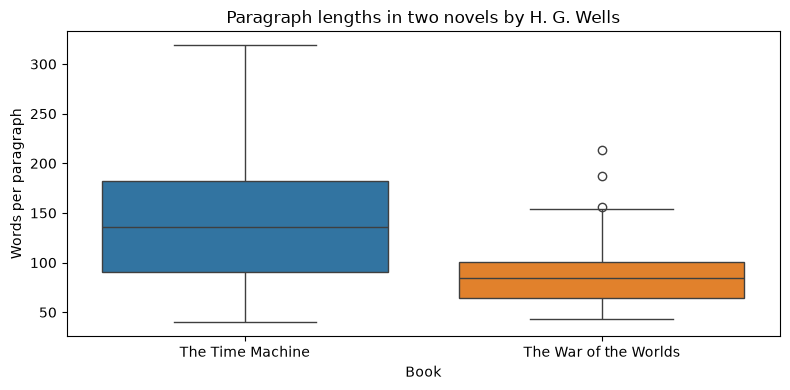

In [55]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=wells, x='book', y='word_count', hue='book', legend=False)
plt.title('Paragraph lengths in two novels by H. G. Wells')
plt.xlabel('Book')
plt.ylabel('Words per paragraph')
plt.tight_layout()
plt.show()

**What does Figure 1 show? Describe a pattern and record at least one supporting value, identifying its word or text feature, group, and units.**

Your answer: The ranges overlap, but the median was 136 words in The Time Machine and 84.5 in The War of the Worlds.

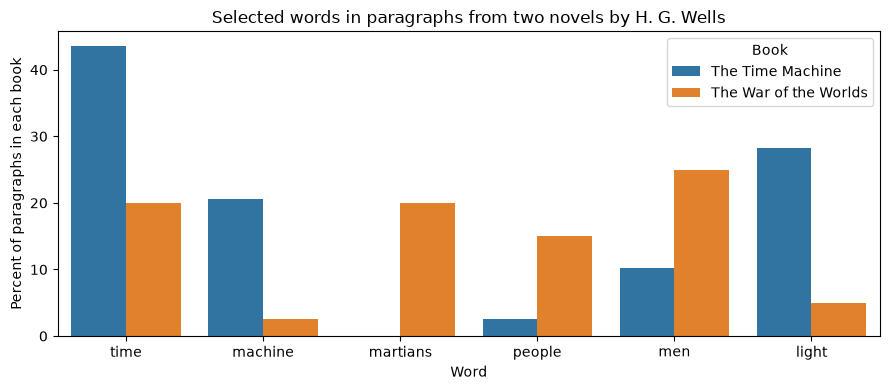

In [56]:
book_words = ['time', 'machine', 'martians', 'people', 'men', 'light']
book_terms = document_percentages(wells, 'book', book_words)
plt.figure(figsize=(9, 4))
sns.barplot(data=book_terms, x='word', y='percent', hue='book', order=book_words)
plt.title('Selected words in paragraphs from two novels by H. G. Wells')
plt.xlabel('Word')
plt.ylabel('Percent of paragraphs in each book')
plt.legend(title='Book')
plt.tight_layout()
plt.show()

**What does Figure 2 add? Record at least one supporting value and compare its message with Figure 1.**

Your answer: Time appeared in 17 of 39 paragraphs from The Time Machine and 8 of 40 from The War of the Worlds. The length chart shows how long the paragraphs were, and the bar chart shows differences in what they say.

### Step 4: Check

Verify at least two plotted values against records or calculated summaries. Read a few original texts containing a selected word or illustrating a pattern, using the lecture's sample function or your own code. For grouped comparisons, check examples from each relevant group when matches exist. Explain whether context supports your interpretation. Do not repeat the initial missing-value count.


In [57]:
time_text = wells_df.loc[(wells_df['book'] == 'The Time Machine') & (wells_df['paragraph_id'] != '35-309'), 'text']
war_text = wells_df.loc[wells_df['book'] == 'The War of the Worlds', 'text']
time_median = time_text.map(lambda text: len(re.findall(word_pattern, text))).median()
light_count = war_text.str.contains(r'\blight\b', case=False).sum()
plotted_light = book_terms.loc[(book_terms['book'] == 'The War of the Worlds') & (book_terms['word'] == 'light')].iloc[0]
assert time_median == wells.loc[wells['book'] == 'The Time Machine', 'word_count'].median()
assert light_count == plotted_light['documents_with_word']
assert len(war_text) == plotted_light['group_documents']
print(f'Median in The Time Machine: {time_median:g} words')
print(f'Paragraphs containing light in The War of the Worlds: {light_count} of {len(war_text)}')

examples = wells.loc[wells['words'].map(lambda words: 'light' in words)]
for row in examples.groupby('book').head(1).itertuples(index=False):
    match = re.search(r'\blight\b', row.text, re.IGNORECASE)
    excerpt = row.text[max(0, match.start() - 75):match.end() + 75]
    print(row.book, row.paragraph_id, '...', excerpt, '...')

Median in The Time Machine: 136 words
Paragraphs containing light in The War of the Worlds: 2 of 40
The Time Machine 35-88 ... For a moment he hesitated in the doorway, as if he had been dazzled by the light. Then he came into the room. He walked with just such a limp as I have see ...
The War of the Worlds 36-12 ... m the perfect round. But so little it was, so silvery warm—a pin’s head of light! It was as if it quivered, but really this was the telescope vibrating wit ...


**Which two values did you check, and did they agree? What did the original text reveal that the figures could not? Describe any correction you made.**

Your answer: Both numbers matched the charts. The median was 136 words for The Time Machine, and 'light' showed up in 2 out of 40 paragraphs from The War of the Worlds. In one example it meant glare in a doorway. In the other, it was a tiny point seen through a telescope.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include numerical values with clear units or denominators and explain whether the evidence supports your prediction.


**Restate your question and write your conclusion.**

Your answer: How do the two books compare in paragraph length and word choice? The lengths overlapped like I expected. The median was 136 words for The Time Machine and 84.5 for The War of the Worlds. 'Time' showed up in 17 out of 39 paragraphs in The Time Machine and 8 out of 40 in The War of the Worlds. For 'machine', it was 8 out of 39 and 1 out of 40. Both words showed up more often in The Time Machine, like I expected.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of your question are easier or harder to answer from each figure.


**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer: I skipped short paragraphs, so the sample leaves out a lot of dialogue. Both books are by H. G. Wells, so I can't use this to draw conclusions about other authors. The box plot shows how long the paragraphs were. The bars show how often words showed up. The examples show what those words meant.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I used ChatGPT to confirm that I counted each word once per document correctly, then had it check the chart counts for `airworthiness` and `light` against the original titles and paragraphs.

## Submission checklist

- Include two distinct text datasets and document their sources, feature definitions, collection context, and access dates.
- Review the datasets and displayed language for work appropriateness; document any screening and its effects.
- Ask one research question per dataset and complete all six steps for each question.
- Complete both feature tables and every written response.
- Include four finished figures: two different chart types per question, with at least one numerical comparison per pair.
- Explain text preparation, stopwords, filtering, missing or blank text, duplicates, group sizes, and row counts.
- Define what is counted and the denominator of every percentage.
- Check two plotted values and original text context for each investigation.
- Restate each question in its conclusion and cite evidence from both figures.
- Identify two limitations per investigation and compare what the displays reveal or obscure.
- Include your data files and any preparation code using relative paths. Complete the AI-use reflection, restart the kernel, and run cells in order before submitting.
